<a href="https://colab.research.google.com/github/martian1998/AWS_hack/blob/main/leakage_free_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q onnx onnxruntime numpy pillow pandas matplotlib scikit-learn

In [6]:
!unzip -q biometric_security_phase1_notebook.zip -d /content

In [7]:
from pathlib import Path
import hashlib
import io
import json
import pickle
import time

import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import roc_auc_score

SEED = 0
N_SPLITS = 10
N_QUANT_CALIB_PAIRS = 50
N_PAIRS = None          # Use None later for the complete dataset
FAR_TARGET = 0.01
BUDGETS = (0.005, 0.01, 0.02, 0.05, 0.10, 0.20)
FORCE_REQUANTIZE = False

In [8]:
candidate_roots = [
    Path("/content/handout 2"),
    Path("/content/handout"),
    Path("/content/biometric_security_phase1_notebook/handout"),
    Path("."),
]

# Also search automatically, including folders containing spaces.
discovered_models = list(Path("/content").glob("**/models/w600k_r50.onnx"))
candidate_roots += [p.parent.parent for p in discovered_models]

ROOT = next(
    (
        p for p in candidate_roots
        if (p / "models/w600k_r50.onnx").exists()
        and (p / "data/lfw.bin").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find models/w600k_r50.onnx and data/lfw.bin under /content"
    )

FP32_PATH = ROOT / "models" / "w600k_r50.onnx"
LFW_BIN_PATH = ROOT / "data" / "lfw.bin"
OUT_DIR = ROOT / "results"
INT8_PATH = OUT_DIR / "w600k_r50_int8.onnx"

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)
print("FP32 model:", FP32_PATH)
print("LFW dataset:", LFW_BIN_PATH)
print("Output folder:", OUT_DIR)

Project folder: /content/handout 2
FP32 model: /content/handout 2/models/w600k_r50.onnx
LFW dataset: /content/handout 2/data/lfw.bin
Output folder: /content/handout 2/results


In [9]:
def load_lfw_bin(path, n_pairs=None, seed=SEED):
    with open(path, "rb") as f:
        bins, issame = pickle.load(f, encoding="bytes")

    labels = np.asarray(issame, dtype=int)

    if n_pairs is not None:
        if n_pairs % 2:
            raise ValueError("N_PAIRS must be even")

        rng = np.random.RandomState(seed)

        chosen = np.concatenate([
            rng.choice(
                np.where(labels == cls)[0],
                n_pairs // 2,
                replace=False
            )
            for cls in (0, 1)
        ])

        chosen = np.sort(chosen)
        bins = [bins[2 * i + j] for i in chosen for j in (0, 1)]
        labels = labels[chosen]

    images = [
        np.asarray(Image.open(io.BytesIO(raw)).convert("RGB"))
        for raw in bins
    ]

    img_a = np.stack(images[0::2])
    img_b = np.stack(images[1::2])

    if img_a.shape[1:] != (112, 112, 3):
        raise ValueError(f"Unexpected image shape: {img_a.shape}")

    return img_a, img_b, labels


def image_key(image):
    return hashlib.sha256(
        np.ascontiguousarray(image).tobytes()
    ).hexdigest()


def make_leakage_free_plan(
    img_a,
    img_b,
    labels,
    n_calib_pairs=N_QUANT_CALIB_PAIRS,
    n_splits=N_SPLITS,
    seed=SEED,
):
    labels = np.asarray(labels, dtype=int)

    if n_calib_pairs % 2:
        raise ValueError("Calibration pair count must be even")

    pair_keys = [
        (image_key(img_a[i]), image_key(img_b[i]))
        for i in range(len(labels))
    ]

    rng = np.random.RandomState(seed)
    selected_pairs = []
    used_images = set()
    pairs_per_class = n_calib_pairs // 2

    # Select 25 positive and 25 negative pairs whose images do not overlap.
    for cls in (0, 1):
        candidates = rng.permutation(np.where(labels == cls)[0])

        for pair_index in candidates:
            pair_index = int(pair_index)
            current_keys = set(pair_keys[pair_index])

            if current_keys & used_images:
                continue

            selected_pairs.append(pair_index)
            used_images.update(current_keys)

            selected_count = sum(
                labels[i] == cls for i in selected_pairs
            )

            if selected_count == pairs_per_class:
                break

        selected_count = sum(
            labels[i] == cls for i in selected_pairs
        )

        if selected_count != pairs_per_class:
            raise RuntimeError(
                "Could not create an image-disjoint calibration set"
            )

    calibration_pair_indices = np.array(
        sorted(selected_pairs),
        dtype=int
    )

    calibration_images = np.concatenate(
        [
            img_a[calibration_pair_indices],
            img_b[calibration_pair_indices],
        ],
        axis=0,
    )

    # Remove every pair that shares an image with the calibration set.
    evaluation_pair_indices = np.array(
        [
            i
            for i, keys in enumerate(pair_keys)
            if not (set(keys) & used_images)
        ],
        dtype=int,
    )

    # Create 10 repeated stratified 50/50 calibration/test splits.
    splits = []

    for _ in range(n_splits):
        split_calibration = []
        split_test = []

        for cls in (0, 1):
            class_indices = evaluation_pair_indices[
                labels[evaluation_pair_indices] == cls
            ]

            class_indices = rng.permutation(class_indices)
            midpoint = len(class_indices) // 2

            split_calibration.append(class_indices[:midpoint])
            split_test.append(class_indices[midpoint:])

        splits.append(
            (
                np.sort(np.concatenate(split_calibration)),
                np.sort(np.concatenate(split_test)),
            )
        )

    return {
        "calibration_images": calibration_images,
        "calibration_pair_indices": calibration_pair_indices,
        "evaluation_pair_indices": evaluation_pair_indices,
        "splits": splits,
    }


img_a, img_b, labels = load_lfw_bin(
    LFW_BIN_PATH,
    n_pairs=N_PAIRS,
    seed=SEED,
)

plan = make_leakage_free_plan(img_a, img_b, labels)

calibration_images = plan["calibration_images"]
evaluation_pair_indices = plan["evaluation_pair_indices"]
splits = plan["splits"]

print("Input pairs:", len(labels))
print("INT8 calibration images:", len(calibration_images))
print("Evaluation pairs:", len(evaluation_pair_indices))
print("Number of splits:", len(splits))

Input pairs: 6000
INT8 calibration images: 100
Evaluation pairs: 5854
Number of splits: 10


In [10]:
import onnx
import onnxruntime as ort

from onnx import version_converter
from onnxruntime.quantization import (
    CalibrationMethod,
    QuantFormat,
    QuantType,
    quantize_static,
)


class OrtEmbedder:
    def __init__(self, model_path, threads=0):
        options = ort.SessionOptions()

        if threads:
            options.intra_op_num_threads = threads

        self.session = ort.InferenceSession(
            str(model_path),
            options,
            providers=["CPUExecutionProvider"],
        )

        input_info = self.session.get_inputs()[0]
        self.input_name = input_info.name

        self.fixed_batch = (
            input_info.shape[0]
            if isinstance(input_info.shape[0], int)
            else None
        )

    @staticmethod
    def prepare(images):
        values = (images.astype(np.float32) - 127.5) / 127.5
        return np.ascontiguousarray(
            values.transpose(0, 3, 1, 2)
        )

    def embed(self, images, batch_size=32):
        batch_size = self.fixed_batch or batch_size
        outputs = []

        for start in range(0, len(images), batch_size):
            chunk = images[start:start + batch_size]
            count = len(chunk)

            if self.fixed_batch and count < batch_size:
                chunk = np.concatenate(
                    [
                        chunk,
                        np.repeat(
                            chunk[-1:],
                            batch_size - count,
                            axis=0,
                        ),
                    ]
                )

            output = self.session.run(
                None,
                {self.input_name: self.prepare(chunk)},
            )[0]

            outputs.append(output[:count])

        embeddings = np.concatenate(outputs)
        norms = np.linalg.norm(
            embeddings,
            axis=1,
            keepdims=True,
        )

        return embeddings / np.maximum(norms, 1e-12)


class CalibrationReader:
    def __init__(self, images, input_name, batch_size):
        batches = []

        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size]

            if len(batch) == batch_size:
                batches.append(
                    {
                        input_name: OrtEmbedder.prepare(batch)
                    }
                )

        self.batches = iter(batches)

    def get_next(self):
        return next(self.batches, None)


fp32 = OrtEmbedder(FP32_PATH)

opset13_path = OUT_DIR / "w600k_r50_opset13.onnx"

if not opset13_path.exists() or FORCE_REQUANTIZE:
    converted_model = version_converter.convert_version(
        onnx.load(str(FP32_PATH)),
        13,
    )
    onnx.save(converted_model, str(opset13_path))

if not INT8_PATH.exists() or FORCE_REQUANTIZE:
    calibration_reader = CalibrationReader(
        calibration_images,
        fp32.input_name,
        fp32.fixed_batch or 1,
    )

    quantize_static(
        str(opset13_path),
        str(INT8_PATH),
        calibration_reader,
        quant_format=QuantFormat.QDQ,
        per_channel=True,
        reduce_range=False,
        weight_type=QuantType.QUInt8,
        activation_type=QuantType.QUInt8,
        op_types_to_quantize=["Conv", "MatMul", "Gemm"],
        calibrate_method=CalibrationMethod.MinMax,
    )

    quant_report = {
        "method": "post_training_static_quantization",
        "variant": "w_u8_a_u8",
        "calibration_images": int(len(calibration_images)),
        "image_disjoint_from_evaluation": True,
    }

    (OUT_DIR / "quant_report.json").write_text(
        json.dumps(quant_report, indent=2)
    )

int8 = OrtEmbedder(INT8_PATH)

print(
    f"FP32 size: {FP32_PATH.stat().st_size / 1e6:.1f} MB"
)
print(
    f"INT8 size: {INT8_PATH.stat().st_size / 1e6:.1f} MB"
)

FP32 size: 174.4 MB
INT8 size: 44.0 MB


In [11]:
def pair_scores(model, image_a, image_b):
    embeddings_a = model.embed(image_a)
    embeddings_b = model.embed(image_b)

    return np.sum(embeddings_a * embeddings_b, axis=1)


eval_a = img_a[evaluation_pair_indices]
eval_b = img_b[evaluation_pair_indices]
eval_labels = labels[evaluation_pair_indices]

scores_fp32 = pair_scores(fp32, eval_a, eval_b)
scores_int8 = pair_scores(int8, eval_a, eval_b)

np.savez(
    OUT_DIR / "embeddings.npz",
    s_fp32=scores_fp32,
    s_int8=scores_int8,
    labels=eval_labels,
)

print(
    "FP32 AUC:",
    round(roc_auc_score(eval_labels, scores_fp32), 6),
)

print(
    "INT8 AUC:",
    round(roc_auc_score(eval_labels, scores_int8), 6),
)

print(
    "Score correlation:",
    round(
        np.corrcoef(scores_fp32, scores_int8)[0, 1],
        6,
    ),
)

FP32 AUC: 0.999402
INT8 AUC: 0.99933
Score correlation: 0.99951


In [14]:
def threshold_at_far(negative_scores, far=FAR_TARGET):
    negatives = np.sort(np.asarray(negative_scores))

    index = max(
        0,
        min(
            len(negatives) - 1,
            int(np.ceil((1 - far) * len(negatives)) - 1),
        ),
    )

    return float(negatives[index])


def margin_for_budget(scores, threshold, budget):
    if budget <= 0:
        return 0.0

    return float(
        np.quantile(
            np.abs(scores - threshold),
            budget,
        )
    )


def evaluate_split(
    s_int8,
    s_fp32,
    labels,
    calibration_indices,
    test_indices,
):
    calibration_labels = labels[calibration_indices]

    tau_int8 = threshold_at_far(
        s_int8[calibration_indices][calibration_labels == 0]
    )

    tau_fp32 = threshold_at_far(
        s_fp32[calibration_indices][calibration_labels == 0]
    )

    test_labels = labels[test_indices]

    fp32_reference = (
        s_fp32[test_indices] >= tau_fp32
    )

    rows = []

    def add_result(name, decisions, escalated):
        positive = test_labels == 1
        negative = test_labels == 0

        rows.append(
            {
                "system": name,
                "TAR": float(decisions[positive].mean()),
                "FAR": float(decisions[negative].mean()),
                "accuracy": float(
                    np.mean(decisions == (test_labels == 1))
                ),
                "agreement_FP32": float(
                    np.mean(decisions == fp32_reference)
                ),
                "escalation": float(np.mean(escalated)),
            }
        )

    add_result(
        "FP32 (reference)",
        fp32_reference,
        np.ones(len(test_indices), dtype=bool),
    )

    add_result(
        "INT8 only",
        s_int8[test_indices] >= tau_int8,
        np.zeros(len(test_indices), dtype=bool),
    )

    for budget in BUDGETS:
        delta = margin_for_budget(
            s_int8[calibration_indices],
            tau_int8,
            budget,
        )

        escalated = (
            np.abs(s_int8[test_indices] - tau_int8)
            < delta
        )

        two_tier_decisions = np.where(
            escalated,
            s_fp32[test_indices] >= tau_fp32,
            s_int8[test_indices] >= tau_int8,
        )

        add_result(
            f"Two-tier (margin) b={budget:g}",
            two_tier_decisions,
            escalated,
        )

        random_generator = np.random.RandomState(
            int(budget * 100000) + len(test_indices)
        )

        random_escalated = (
            random_generator.random(len(test_indices))
            < escalated.mean()
        )

        random_decisions = np.where(
            random_escalated,
            s_fp32[test_indices] >= tau_fp32,
            s_int8[test_indices] >= tau_int8,
        )

        add_result(
            f"Random escalation b={budget:g}",
            random_decisions,
            random_escalated,
        )

    return rows


# Convert original pair indices to local score-array indices.
local_index = {
    int(original_index): local_index
    for local_index, original_index
    in enumerate(evaluation_pair_indices)
}

all_rows = []

for split_number, (global_calibration, global_test) in enumerate(splits):
    calibration_indices = np.array(
        [local_index[int(i)] for i in global_calibration],
        dtype=int,
    )

    test_indices = np.array(
        [local_index[int(i)] for i in global_test],
        dtype=int,
    )

    split_rows = evaluate_split(
        scores_int8,
        scores_fp32,
        eval_labels,
        calibration_indices,
        test_indices,
    )

    for row in split_rows:
        row["split"] = split_number
        all_rows.append(row)

results = pd.DataFrame(all_rows)

results.to_csv(
    OUT_DIR / "all_splits.csv",
    index=False,
)

summary_mean = results.groupby(
    "system"
).mean(numeric_only=True)

summary_std = results.groupby(
    "system"
).std(numeric_only=True)

summary_mean.to_csv(
    OUT_DIR / "summary_mean.csv"
)

summary_std.to_csv(
    OUT_DIR / "summary_std.csv"
)

print(summary_mean)

                                TAR       FAR  accuracy  agreement_FP32  \
system                                                                    
FP32 (reference)           0.997674  0.011392  0.993135        1.000000   
INT8 only                  0.997606  0.011528  0.993033        0.998122   
Random escalation b=0.005  0.997606  0.011528  0.993033        0.998122   
Random escalation b=0.01   0.997606  0.011528  0.993033        0.998122   
Random escalation b=0.02   0.997606  0.011528  0.993033        0.998122   
Random escalation b=0.05   0.997606  0.011255  0.993169        0.998258   
Random escalation b=0.1    0.997674  0.011460  0.993101        0.998327   
Random escalation b=0.2    0.997674  0.011664  0.992999        0.998634   
Two-tier (margin) b=0.005  0.997674  0.010914  0.993374        0.999693   
Two-tier (margin) b=0.01   0.997674  0.011119  0.993272        0.999863   
Two-tier (margin) b=0.02   0.997674  0.011392  0.993135        1.000000   
Two-tier (margin) b=0.05 

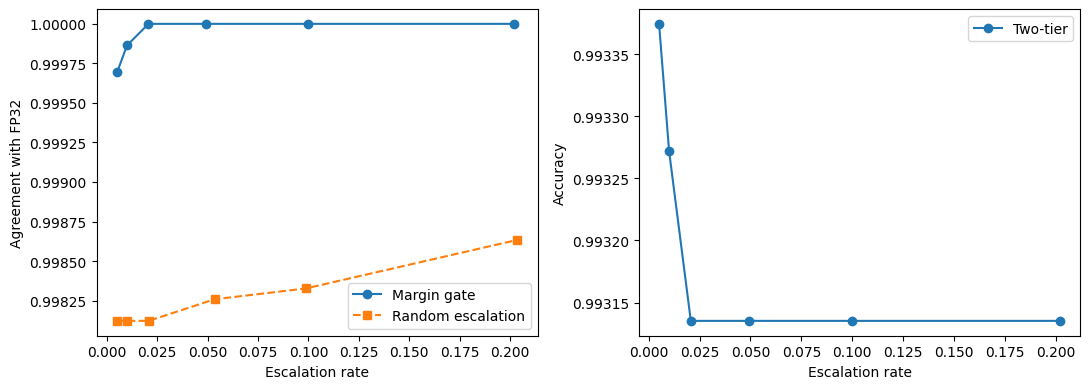

Results saved to:
/content/handout 2/results


In [15]:
import matplotlib.pyplot as plt

margin_results = results[
    results["system"].str.startswith("Two-tier (margin)")
].groupby("system").mean(numeric_only=True)

random_results = results[
    results["system"].str.startswith("Random escalation")
].groupby("system").mean(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    margin_results["escalation"],
    margin_results["agreement_FP32"],
    "o-",
    label="Margin gate",
)

axes[0].plot(
    random_results["escalation"],
    random_results["agreement_FP32"],
    "s--",
    label="Random escalation",
)

axes[0].set_xlabel("Escalation rate")
axes[0].set_ylabel("Agreement with FP32")
axes[0].legend()

axes[1].plot(
    margin_results["escalation"],
    margin_results["accuracy"],
    "o-",
    label="Two-tier",
)

axes[1].set_xlabel("Escalation rate")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

fig.tight_layout()
fig.savefig(
    OUT_DIR / "agreement_vs_escalation.png",
    dpi=150,
)

plt.show()

metadata = {
    "n_input_pairs": int(len(labels)),
    "n_evaluation_pairs": int(len(eval_labels)),
    "n_quant_calibration_images": int(len(calibration_images)),
    "n_splits": N_SPLITS,
    "far_target": FAR_TARGET,
    "auc_fp32": float(
        roc_auc_score(eval_labels, scores_fp32)
    ),
    "auc_int8": float(
        roc_auc_score(eval_labels, scores_int8)
    ),
    "fp32_model_mb": FP32_PATH.stat().st_size / 1e6,
    "int8_model_mb": INT8_PATH.stat().st_size / 1e6,
    "leakage_fix": (
        "image-disjoint quantization calibration holdout"
    ),
}

(OUT_DIR / "meta.json").write_text(
    json.dumps(metadata, indent=2)
)

print("Results saved to:")
print(OUT_DIR)